In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")

In [2]:
customers = pd.read_csv(r"D:\Customer Segmentation Analysis\data\processed\customers_cleaned.csv")
transactions = pd.read_csv(r"D:\Customer Segmentation Analysis\data\processed\transactions_cleaned.csv")
products = pd.read_csv(r"D:\Customer Segmentation Analysis\data\processed\products_cleaned.csv")
annual_summary = pd.read_csv(r"D:\Customer Segmentation Analysis\data\processed\annual_summary_cleaned.csv")

# Convert date columns
customers["SignupDate"] = pd.to_datetime(customers["SignupDate"])
transactions["OrderDate"] = pd.to_datetime(transactions["OrderDate"])

print("All cleaned datasets loaded successfully!")

All cleaned datasets loaded successfully!


In [4]:
# Calculating main buiness metrices

total_customers = customers["CustomerID"].nunique()
total_transactions = transactions["TransactionID"].nunique()
total_products = products["ProductID"].nunique()

total_revenue = transactions["Sales"].sum()
total_profit = transactions["Profit"].sum()
total_quantity = transactions["Quantity"].sum()

avg_order_value = transactions["Sales"].mean()

print("Total Customers:", total_customers)
print("Total Transactions:", total_transactions)
print("Total Products:", total_products)
print("Total Revenue:", round(total_revenue, 2))
print("Total Profit:", round(total_profit, 2))
print("Total Quantity Sold:", total_quantity)
print("Average Transaction Value:", round(avg_order_value, 2))

Total Customers: 6500
Total Transactions: 32500
Total Products: 18
Total Revenue: 9370458.94
Total Profit: 3419709.27
Total Quantity Sold: 97595
Average Transaction Value: 288.32


In [5]:
# sales changes over years:

transactions["Year"] = transactions["OrderDate"].dt.year
yearly_sales = transactions.groupby("Year")["Sales"].sum()
print(yearly_sales)

Year
2021     438385.02
2022    1177692.17
2023    1855222.36
2024    2664583.38
2025    3234576.01
Name: Sales, dtype: float64


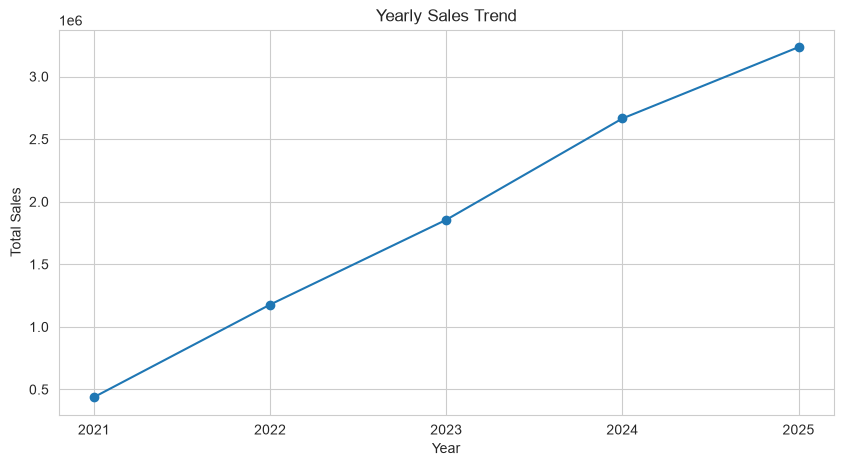

In [8]:
# Visualization:

plt.figure(figsize=(10, 5))

yearly_sales.plot(kind="line", marker="o")

plt.title("Yearly Sales Trend")
plt.xlabel("Year")
plt.ylabel("Total Sales")
plt.xticks(yearly_sales.index)
plt.grid(True)

plt.show()

In [9]:
# Sales by product category

category_sales = transactions.merge(
    products[["ProductID", "Category"]],
    on = "ProductID",
    how = "left"
)

category_revenue = category_sales.groupby("Category")["Sales"].sum().sort_values(
    ascending = False
)
print(category_revenue)

Category
Electronics       1884126.63
Sports            1754864.68
Home & Kitchen    1660389.50
Beauty            1654166.17
Fashion           1584868.78
Books              832043.18
Name: Sales, dtype: float64


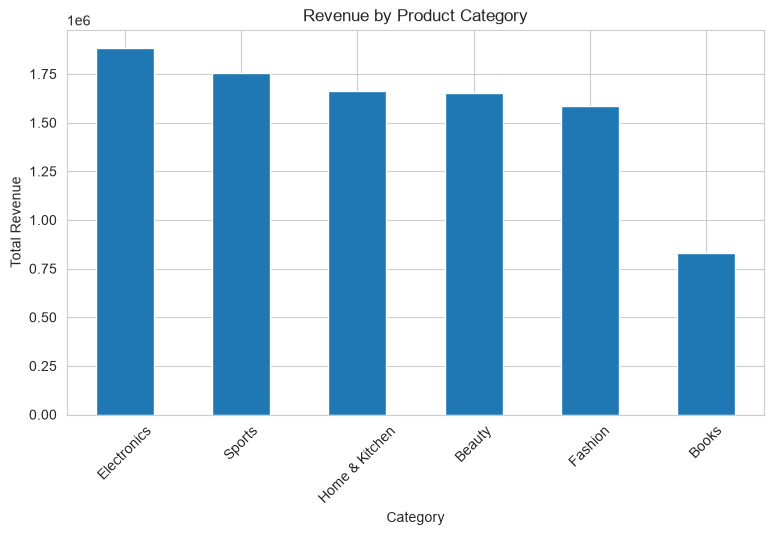

In [10]:
# visualization of Sales by product category

plt.figure(figsize=(9, 5))

category_revenue.plot(kind="bar")

plt.title("Revenue by Product Category")
plt.xlabel("Category")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)

plt.show()

In [11]:
# Sales by region

regional_sales = transactions.merge(
    customers[["CustomerID", "Region"]],
    on="CustomerID",
    how="left"
)

region_revenue = regional_sales.groupby("Region")["Sales"].sum().sort_values(
    ascending=False
)

print(region_revenue)

Region
West       1920948.29
North      1919407.87
East       1916574.49
South      1840401.43
Central    1773126.86
Name: Sales, dtype: float64


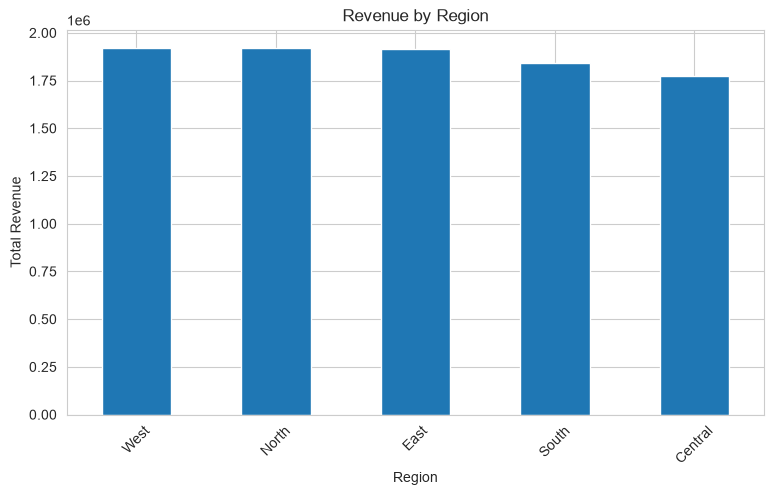

In [12]:
# visualization of sales by region

plt.figure(figsize=(9, 5))

region_revenue.plot(kind="bar")

plt.title("Revenue by Region")
plt.xlabel("Region")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)

plt.show()

In [13]:
# Customer Acquisition Channels

channel_customers = customers["AcquisitionChannel"].value_counts()
print(channel_customers)

AcquisitionChannel
Website           1828
Mobile App        1742
Social Media       980
Email Campaign     849
Referral           578
In-Store           523
Name: count, dtype: int64


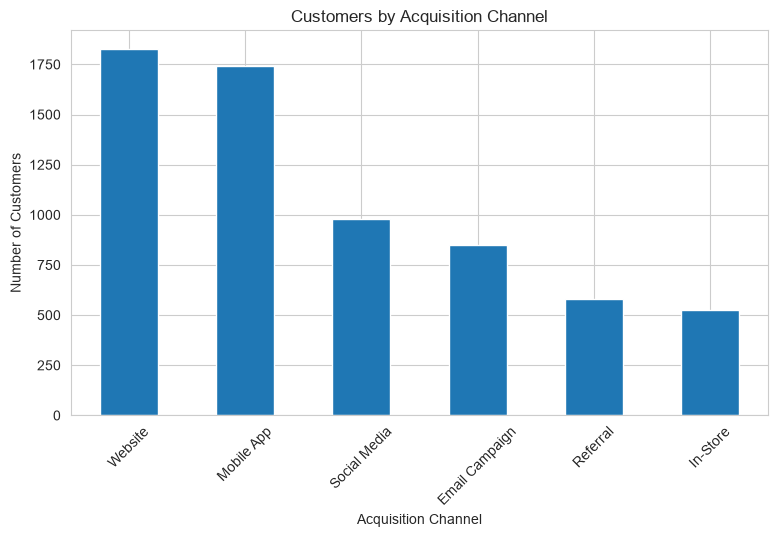

In [14]:
# Visualization of customer acquisition channels

plt.figure(figsize=(9, 5))

channel_customers.plot(kind="bar")

plt.title("Customers by Acquisition Channel")
plt.xlabel("Acquisition Channel")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45)

plt.show()

In [15]:
# revenue by acquisition channel

customer_transactions = transactions.merge(
    customers[["CustomerID", "AcquisitionChannel"]],
    on = "CustomerID",
    how = "left"
)

channel_revenue = customer_transactions.groupby(
    "AcquisitionChannel" 
)["Sales"].sum().sort_values(ascending = False)

print(channel_revenue)

AcquisitionChannel
Website           2639749.98
Mobile App        2482842.17
Social Media      1351613.05
Email Campaign    1262232.74
Referral           860275.71
In-Store           773745.29
Name: Sales, dtype: float64


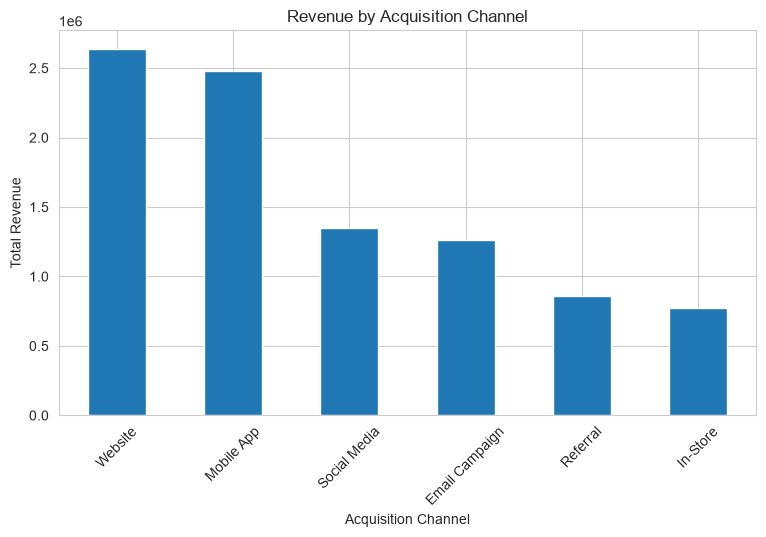

In [16]:
# visualization of revenue by acquisition channel

plt.figure(figsize=(9, 5))

channel_revenue.plot(kind="bar")

plt.title("Revenue by Acquisition Channel")
plt.xlabel("Acquisition Channel")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)

plt.show()

In [18]:
# analysis of active and inactive customers

active_customers = transactions["CustomerID"].nunique()
total_customers = customers["CustomerID"].nunique()
inactive_customers = total_customers - active_customers

print("Total Customers:", total_customers)
print("Active Customers:", active_customers)
print("Inactive Customers:", inactive_customers)

Total Customers: 6500
Active Customers: 6232
Inactive Customers: 268


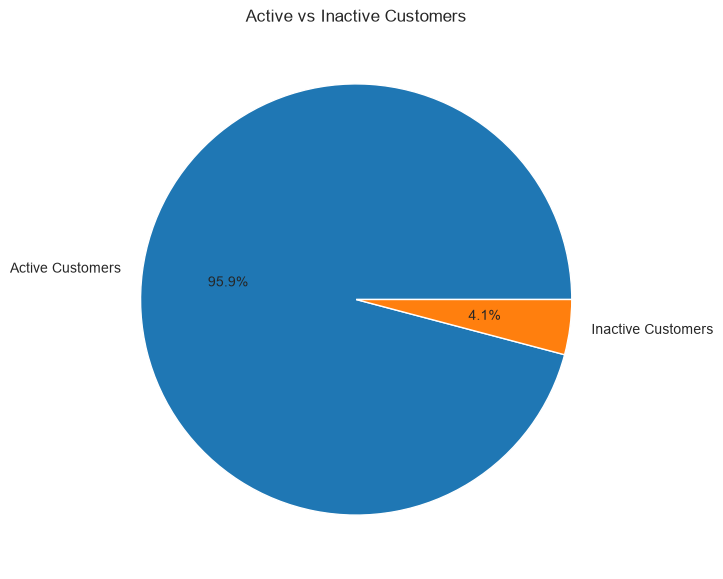

In [19]:
# visualization of active and inactive customers

customer_status = pd.Series({
    "Active Customers": active_customers,
    "Inactive Customers": inactive_customers
})

customer_status.plot(
    kind="pie",
    autopct="%1.1f%%",
    figsize=(7, 7)
)

plt.title("Active vs Inactive Customers")
plt.ylabel("")

plt.show()